**Universidade Federal do Rio Grande do Norte**

**Disciplina:** PPGEEC2327 - Tópicos Especiais em Processamento Inteligente da Informação

**Discente:** José Augusto Agripino de Oliveira

# Filtragem de artefatos de migração com FCNN e SVM (kernel RBF)

Laboratório: [Identifying Migration Artifacts and Reflectors by Machine Learning Methods](http://utam.gg.utah.edu/Classes/ML/LAB1/Chapter.Book.SVM/lab.html) (Y. Chen), pacote `Comparision.zip`.

Cada pixel da imagem migrada é descrito por 3 atributos: coerência, ângulo de mergulho e amplitude. No próprio notebook você marca **50 artefatos** ($y=0$) e **30 refletores** ($y=1$). A FCNN e a SVM-RBF são treinadas com esses pontos e depois classificam os $201\times201$ pixels. A filtragem é o *mute* dos pixels classificados como artefato.

O código MATLAB do lab (`compare_main.m`, `nnCostFunction.m`, `svmTrain.m`, `svmPredict2.m`) foi traduzido para Python.

**Como executar:** a seção 2 abre uma figura clicável para o picking. Ela precisa do pacote `ipympl`, já instalado nos ambientes `lisa` e `.venv`; se acabou de instalá-lo, reinicie o kernel. Em um kernel sem `ipympl`, a figura abre numa janela separada. Ao terminar o picking, execute as células seguintes.

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import scipy.io as sio
from IPython.display import Markdown, display
import ipywidgets as widgets

plt.rcParams.update({'figure.dpi': 110, 'font.size': 9})
SEMENTE = 0          # inicialização da FCNN e escolha aleatória de j no SMO
COR = {'FCNN': '#2a78d6', 'SVM': '#eb6834'}

## 1. Imagem de migração e atributos

Como no `compare_main.m`, cada atributo é reescalado por $(x-\bar x)/(\max x-\min x)$.

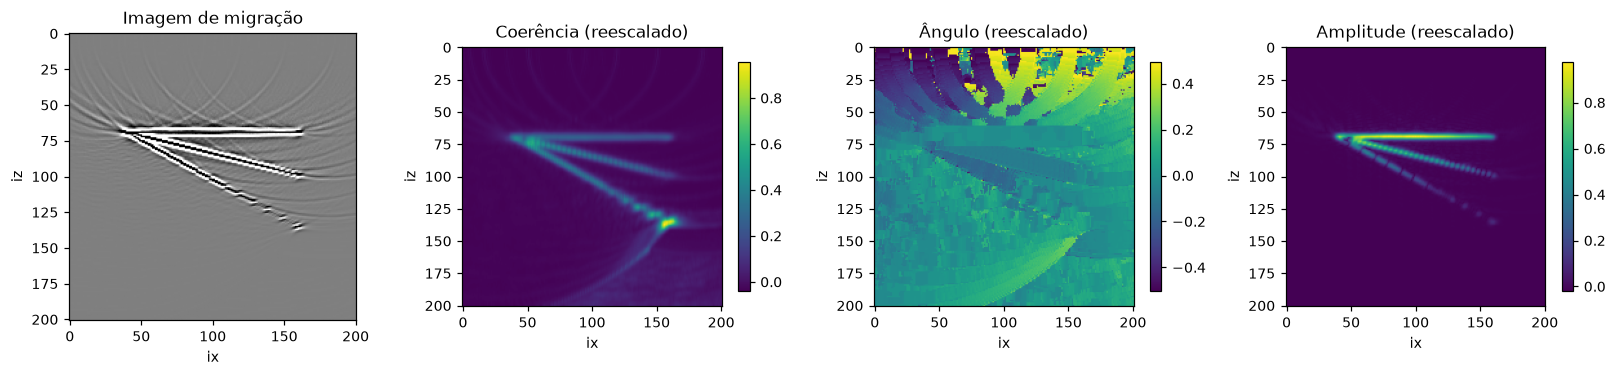

In [2]:
d = sio.loadmat('mig_and_features.mat')
mig = d['mig']
nz, nx = mig.shape
reescala = lambda f: (f - f.mean()) / (f.max() - f.min())
cohe2, angl2, engy2 = reescala(d['cohe']), reescala(d['angl'].astype(float)), reescala(d['engy'])
F = np.stack([cohe2, angl2, engy2], axis=-1)       # (nz, nx, 3): atributos de cada pixel
migN = mig / np.abs(mig).max()                     # Normalize.m

fig, ax = plt.subplots(1, 4, figsize=(15, 3.4))
ax[0].imshow(migN, cmap='gray', vmin=-0.06, vmax=0.06); ax[0].set_title('Imagem de migração')
for a, f, t in zip(ax[1:], [cohe2, angl2, engy2], ['Coerência', 'Ângulo', 'Amplitude']):
    fig.colorbar(a.imshow(f, cmap='viridis'), ax=a, shrink=0.8); a.set_title(t + ' (reescalado)')
for a in ax:
    a.set_xlabel('ix'); a.set_ylabel('iz')
plt.tight_layout(); plt.show()

## 2. Picking manual no notebook

A célula abaixo mostra a imagem migrada (recorte ±0,06, como no lab) numa **figura interativa**. Ela faz o papel do `ginput` do MATLAB.

* **Clique esquerdo** marca um ponto: primeiro os **50 artefatos** (arcos/"sorrisos" de migração, círculos amarelos), depois os **30 refletores** (cruzes vermelhas). O título mostra quantos faltam.
* **Desfazer último ponto** (botão acima da figura) ou **clique direito** remove o último ponto.
* Para dar zoom, use a lupa da barra da figura e desligue-a antes de voltar a clicar. Com a lupa ou a mão ativas, os cliques não marcam pontos.
* Ao completar os 80 pontos, eles são gravados em `picks.csv` (colunas `ix, iz, label`). **Depois, execute a próxima célula.**

Se `picks.csv` já existir, os pontos são reaproveitados. Para refazer o picking, ponha `REFAZER_PICKING = True`; o arquivo anterior é guardado como `picks_anterior.csv`.

**Dica:** distribua os artefatos por todos os arcos, inclusive os fracos da parte rasa (iz < 50), e os refletores pelos três eventos. A SVM-RBF é sensível a regiões do espaço de atributos sem pontos de treino (veja a seção 6).

In [3]:
REFAZER_PICKING = False
N_ARTI, N_REFL = 50, 30
ARQ_PICKS = Path('picks.csv')


class Picking:
    # Equivalente ao ginput do compare_main.m: artefatos (label 0) primeiro, depois refletores (label 1).

    def __init__(self, ax):
        self.ax, self.pontos, self.marcas, self.salvo = ax, [], [], False
        self.atualizar()

    def faltam(self, label):
        return (N_ARTI if label == 0 else N_REFL) - sum(p[2] == label for p in self.pontos)

    def completo(self):
        return self.faltam(0) == 0 and self.faltam(1) == 0

    def clique(self, ev):
        if ev.inaxes is not self.ax or getattr(getattr(ev.canvas, 'toolbar', None), 'mode', ''):
            return                                            # fora da imagem ou zoom/pan ativo
        if ev.button == 3:
            self.desfazer()
        elif ev.button == 1 and not self.completo():
            ix = int(np.clip(round(ev.xdata), 0, nx - 1))
            iz = int(np.clip(round(ev.ydata), 0, nz - 1))
            if any((ix, iz) == p[:2] for p in self.pontos):
                return                                        # pixel já marcado
            label = 0 if self.faltam(0) > 0 else 1
            estilo = dict(marker='o', mfc='yellow', mec='k', ms=6) if label == 0 else dict(marker='+', color='r', mew=2, ms=10)
            self.pontos.append((ix, iz, label))
            self.marcas.append(self.ax.plot(ix, iz, ls='none', **estilo)[0])
            self.atualizar()

    def desfazer(self, *_):
        if self.pontos:
            self.pontos.pop()
            self.marcas.pop().remove()
            self.atualizar()

    def atualizar(self):
        if self.completo():
            np.savetxt(ARQ_PICKS, np.array(self.pontos), fmt='%d', delimiter=',', header='ix,iz,label', comments='')
            self.salvo = True
            txt, cor = f'Concluído: {len(self.pontos)} pontos salvos em {ARQ_PICKS}. Execute a próxima célula.', 'green'
        else:
            if self.salvo:                                    # desfez depois de salvar: o arquivo deixa de valer
                ARQ_PICKS.unlink(missing_ok=True); self.salvo = False
            if self.faltam(0) > 0:
                txt, cor = f'Clique nos ARTEFATOS: faltam {self.faltam(0)} de {N_ARTI}', 'darkgoldenrod'
            else:
                txt, cor = f'Clique nos REFLETORES: faltam {self.faltam(1)} de {N_REFL}', 'red'
        self.ax.set_title(txt, color=cor)
        self.ax.figure.canvas.draw_idle()


if ARQ_PICKS.exists() and not REFAZER_PICKING:
    print(f'Usando os pontos já salvos em {ARQ_PICKS} (REFAZER_PICKING = True para refazer).')
else:
    try:                                                         # figura clicável dentro do notebook (ipympl)
        import ipywidgets as widgets
        get_ipython().run_line_magic('matplotlib', 'widget')
        NO_NOTEBOOK = True
    except (ImportError, RuntimeError):                          # kernel sem ipympl: abre uma janela separada
        get_ipython().run_line_magic('matplotlib', 'tk')
        NO_NOTEBOOK = False
        print('ipympl não encontrado neste kernel: o picking abre numa janela separada (pip install ipympl e reinicie o kernel para clicar no notebook).')
    if ARQ_PICKS.exists():
        ARQ_PICKS.replace('picks_anterior.csv')
    with plt.ioff():
        fig_pick, ax_pick = plt.subplots(figsize=(7.5, 7))
    ax_pick.imshow(migN, cmap='gray', vmin=-0.06, vmax=0.06)
    ax_pick.set_xlabel('ix'); ax_pick.set_ylabel('iz')
    fig_pick.tight_layout()
    picking = Picking(ax_pick)
    fig_pick.canvas.mpl_connect('button_press_event', picking.clique)
    if NO_NOTEBOOK:
        fig_pick.canvas.header_visible = False
        botao = widgets.Button(description='Desfazer último ponto', icon='undo')
        botao.on_click(picking.desfazer)
        display(widgets.VBox([botao, fig_pick.canvas]))
    else:
        plt.show(block=False)


Usando os pontos já salvos em picks.csv (REFAZER_PICKING = True para refazer).


50 artefatos, 30 refletores


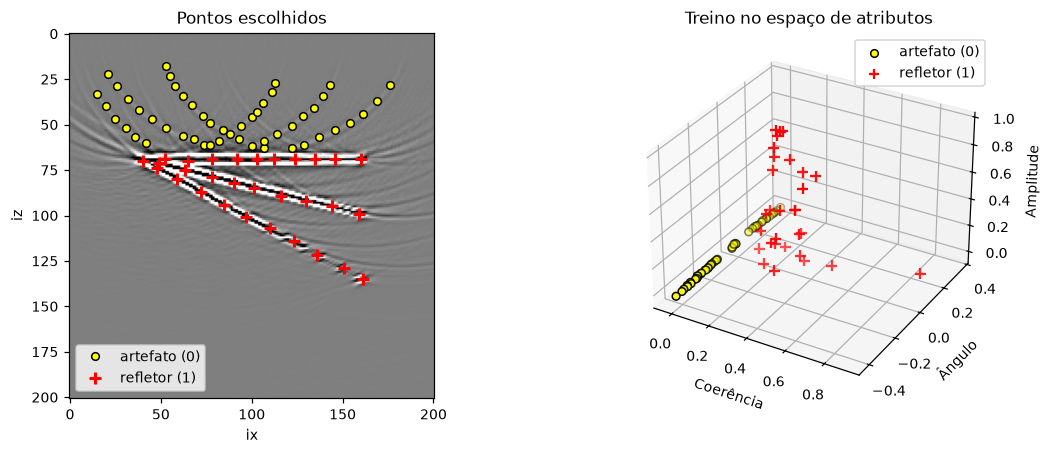

In [4]:
if not ARQ_PICKS.exists():
    raise RuntimeError('Termine o picking na figura acima (50 artefatos + 30 refletores) e execute esta célula de novo.')
plt.close('all')                                                # fecha a figura do picking
get_ipython().run_line_magic('matplotlib', 'inline')          # volta às figuras estáticas

picks = np.loadtxt(ARQ_PICKS, delimiter=',', skiprows=1, dtype=int)    # colunas: ix, iz, label
ix, iz, Y = picks.T
X = F[iz, ix]                                                           # (80, 3)
print(f'{(Y == 0).sum()} artefatos, {(Y == 1).sum()} refletores')


def plot_treino(a):
    a.scatter(*X[Y == 0].T, c='yellow', edgecolors='k', s=25, label='artefato (0)')
    a.scatter(*X[Y == 1].T, c='r', marker='+', s=50, label='refletor (1)')
    a.set_xlabel('Coerência'); a.set_ylabel('Ângulo'); a.set_zlabel('Amplitude')


fig = plt.figure(figsize=(11, 4.2))
a = fig.add_subplot(121)
a.imshow(migN, cmap='gray', vmin=-0.06, vmax=0.06)
a.plot(ix[Y == 0], iz[Y == 0], 'o', mfc='yellow', mec='k', ms=5, label='artefato (0)')
a.plot(ix[Y == 1], iz[Y == 1], 'r+', mew=2, ms=8, label='refletor (1)')
a.legend(loc='lower left'); a.set_title('Pontos escolhidos'); a.set_xlabel('ix'); a.set_ylabel('iz')
a3 = fig.add_subplot(122, projection='3d'); plot_treino(a3); a3.legend(); a3.set_title('Treino no espaço de atributos')
plt.tight_layout(); plt.show()

## 3. FCNN (tradução de `nnCostFunction.m`)

A rede segue o lab:

* **Entradas:** expandidas para termos quadráticos $(x_1,x_2,x_3,x_1^2,x_2^2,x_3^2,x_1x_2,x_1x_3,x_2x_3)$ mais o termo de interceptação.
* **Camadas:** uma camada oculta com 9 neurônios sigmoides e uma saída sigmoide, que dá $P(\text{refletor})$.
* **Treino:** entropia cruzada com $\lambda=0$, gradiente por *backpropagation* e *steepest descent* com passo inicial 10, reduzido por 0,8 enquanto o custo aumentar, por 500 iterações.

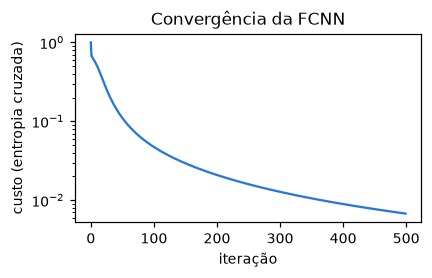

custo final: 0.0068


In [5]:
def expandir(X):
    x1, x2, x3 = X[..., 0], X[..., 1], X[..., 2]
    return np.stack([np.ones_like(x1), x1, x2, x3, x1**2, x2**2, x3**2, x1 * x2, x1 * x3, x2 * x3], axis=-1)


sigmoid = lambda z: 1 / (1 + np.exp(-z))


def fcnn_forward(A, T1, T2):
    a2 = np.column_stack([np.ones(len(A)), sigmoid(A @ T1.T)])     # camada oculta + viés
    return a2, sigmoid(a2 @ T2.T).ravel()


def nn_cost(T1, T2, A, y, lam=0.0):
    m = len(y)
    a2, h = fcnn_forward(A, T1, T2)
    h = np.clip(h, 1e-12, 1 - 1e-12)
    J = -np.mean(y * np.log(h) + (1 - y) * np.log(1 - h)) + lam / (2 * m) * (np.sum(T1[:, 1:]**2) + np.sum(T2[:, 1:]**2))
    d3 = (h - y)[:, None]                                       # erro na saída
    d2 = (d3 @ T2)[:, 1:] * a2[:, 1:] * (1 - a2[:, 1:])         # erro na camada oculta
    G1, G2 = d2.T @ A / m, d3.T @ a2 / m
    G1[:, 1:] += lam / m * T1[:, 1:]
    G2[:, 1:] += lam / m * T2[:, 1:]
    return J, G1, G2


def fcnn_train(X, y, hidden=9, step=10.0, maxiter=500, seed=SEMENTE):
    r = np.random.default_rng(seed)
    A = expandir(X)
    T1 = r.random((hidden, A.shape[1])) - 0.5
    T2 = r.random((1, hidden + 1)) - 0.5
    historico = []
    for _ in range(maxiter):
        J, G1, G2 = nn_cost(T1, T2, A, y)
        N1, N2 = T1 - step * G1, T2 - step * G2
        J1 = nn_cost(N1, N2, A, y)[0]
        while J1 > J:                                           # reduz o passo enquanto o custo aumentar
            step *= 0.8
            N1, N2 = T1 - step * G1, T2 - step * G2
            J1 = nn_cost(N1, N2, A, y)[0]
        T1, T2 = N1, N2
        historico.append(J1)
    return T1, T2, np.array(historico)


def fcnn_predict(X, T1, T2):
    p = fcnn_forward(expandir(X).reshape(-1, 10), T1, T2)[1]
    return (p > 0.5).astype(int).reshape(X.shape[:-1])


t0 = time.perf_counter(); T1, T2, hist = fcnn_train(X, Y.astype(float)); t_nn_train = time.perf_counter() - t0
t0 = time.perf_counter(); res_nn = fcnn_predict(F, T1, T2); t_nn_pred = time.perf_counter() - t0

plt.figure(figsize=(4, 2.6)); plt.semilogy(hist, color=COR['FCNN'])
plt.xlabel('iteração'); plt.ylabel('custo (entropia cruzada)'); plt.title('Convergência da FCNN')
plt.tight_layout(); plt.show()
print(f'custo final: {hist[-1]:.4f}')

## 4. SVM com kernel RBF (tradução de `svmTrain.m` / `svmPredict2.m`)

* **Kernel:** gaussiano, $K(\mathbf x,\mathbf x')=\exp(-\|\mathbf x-\mathbf x'\|^2/2\sigma^2)$, com $C=1$ e $\sigma=0{,}1$ (valores do lab).
* **Treino:** SMO simplificado do `svmTrain.m` (`tol = 1e-3`, `max_passes = 5`, segundo índice $j$ sorteado).
* **Decisão:** $f(\mathbf x)=\sum_i \alpha_i y_i K(\mathbf x_i,\mathbf x)+b$, com refletor quando $f\ge 0$.

**Obs.:** o `svmPredict2.m` original **omite o $b$** no ramo gaussiano. Aqui ele é incluído, e o efeito da omissão é medido na seção 5.3.

In [6]:
def rbf(A, B, sigma):
    d2 = (A**2).sum(1)[:, None] + (B**2).sum(1)[None, :] - 2 * A @ B.T
    return np.exp(-np.maximum(d2, 0) / (2 * sigma**2))


def svm_train(X, Y, C=1.0, sigma=0.1, tol=1e-3, max_passes=5, seed=SEMENTE):
    r = np.random.default_rng(seed)
    y = np.where(Y == 1, 1.0, -1.0)                              # 0 -> -1
    m = len(y)
    K = rbf(X, X, sigma)
    alpha, b, passes = np.zeros(m), 0.0, 0
    while passes < max_passes:
        mudou = 0
        for i in range(m):
            Ei = b + np.sum(alpha * y * K[:, i]) - y[i]
            if (y[i] * Ei < -tol and alpha[i] < C) or (y[i] * Ei > tol and alpha[i] > 0):
                j = r.integers(m - 1); j += j >= i                # j aleatório, j != i
                Ej = b + np.sum(alpha * y * K[:, j]) - y[j]
                ai, aj = alpha[i], alpha[j]
                if y[i] == y[j]:
                    L, H = max(0, aj + ai - C), min(C, aj + ai)
                else:
                    L, H = max(0, aj - ai), min(C, C + aj - ai)
                eta = 2 * K[i, j] - K[i, i] - K[j, j]
                if L == H or eta >= 0:
                    continue
                alpha[j] = np.clip(aj - y[j] * (Ei - Ej) / eta, L, H)
                if abs(alpha[j] - aj) < tol:
                    alpha[j] = aj
                    continue
                alpha[i] = ai + y[i] * y[j] * (aj - alpha[j])
                # mesmas expressões do svmTrain.m
                b1 = b - Ei - y[i] * (alpha[i] - ai) * K[i, j] - y[j] * (alpha[j] - aj) * K[i, j]
                b2 = b - Ej - y[i] * (alpha[i] - ai) * K[i, j] - y[j] * (alpha[j] - aj) * K[j, j]
                b = b1 if 0 < alpha[i] < C else b2 if 0 < alpha[j] < C else (b1 + b2) / 2
                mudou += 1
        passes = passes + 1 if mudou == 0 else 0
    sv = alpha > 0
    return {'X': X[sv], 'y': y[sv], 'alpha': alpha[sv], 'b': b, 'sigma': sigma}


def svm_decision(model, X, com_b=True):
    Xf = X.reshape(-1, X.shape[-1])
    f = rbf(Xf, model['X'], model['sigma']) @ (model['alpha'] * model['y'])
    return (f + (model['b'] if com_b else 0.0)).reshape(X.shape[:-1])


svm_predict = lambda model, X, com_b=True: (svm_decision(model, X, com_b) >= 0).astype(int)

t0 = time.perf_counter(); model = svm_train(X, Y); t_svm_train = time.perf_counter() - t0
t0 = time.perf_counter(); res_svm = svm_predict(model, F); t_svm_pred = time.perf_counter() - t0
print(f"vetores de suporte: {len(model['alpha'])} de {len(Y)}  |  b = {model['b']:+.3f}")

vetores de suporte: 45 de 80  |  b = +0.430


## 5. Comparação

### 5.1 Classificação de todos os pixels e imagens filtradas

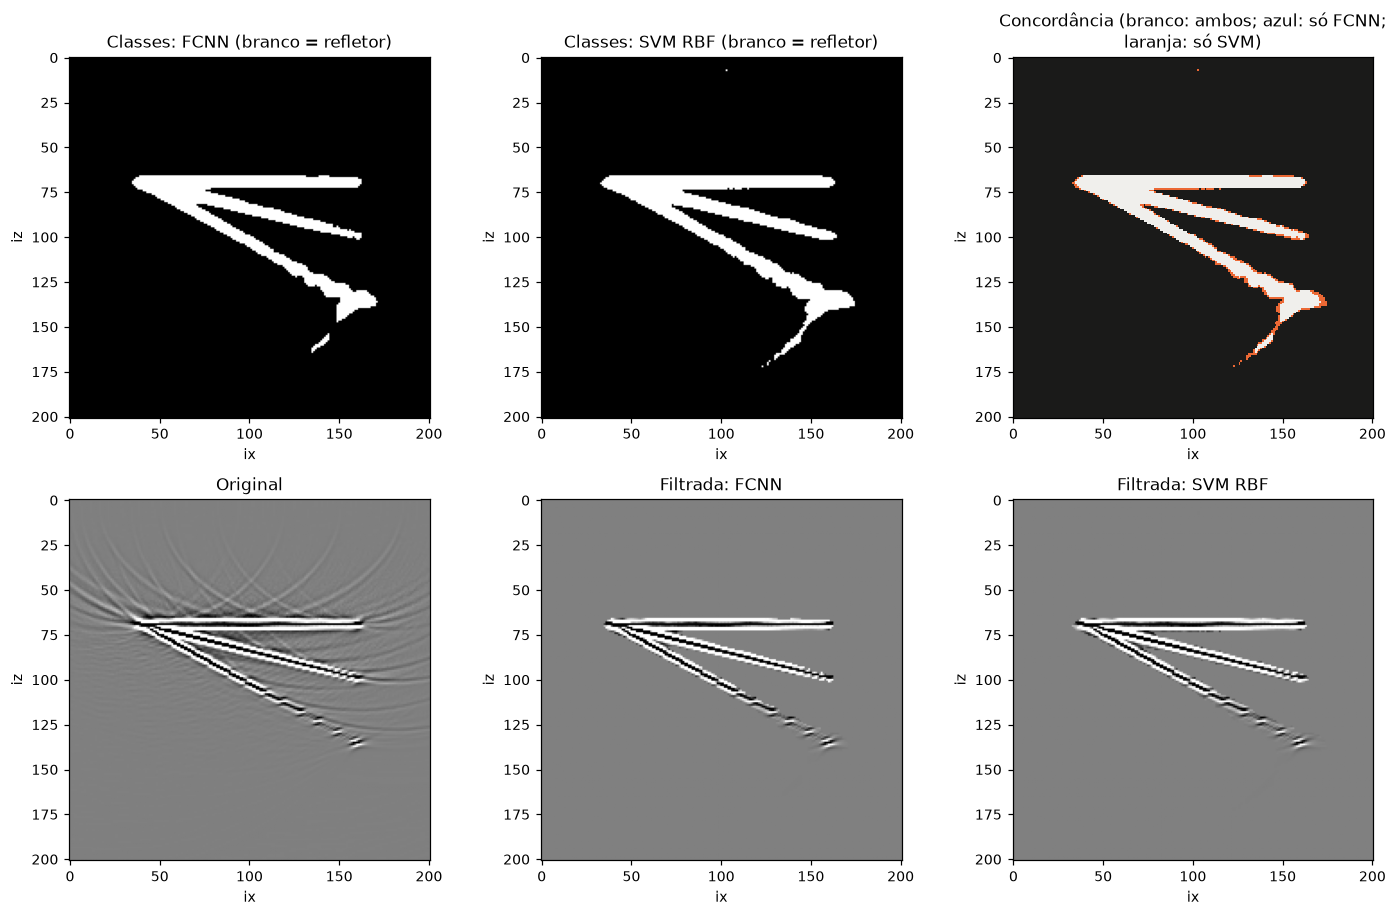

In [7]:
fig, ax = plt.subplots(2, 3, figsize=(13, 8.4))
ax[0, 0].imshow(res_nn, cmap='gray'); ax[0, 0].set_title('Classes: FCNN (branco = refletor)')
ax[0, 1].imshow(res_svm, cmap='gray'); ax[0, 1].set_title('Classes: SVM RBF (branco = refletor)')
ax[0, 2].imshow(res_nn + 2 * res_svm, cmap=ListedColormap(['#1a1a19', COR['FCNN'], COR['SVM'], '#f0efec']), vmin=0, vmax=3,
                interpolation='nearest')
ax[0, 2].set_title('Concordância (branco: ambos; azul: só FCNN;\nlaranja: só SVM)')
for a, img, t in zip(ax[1], [migN, migN * res_nn, migN * res_svm], ['Original', 'Filtrada: FCNN', 'Filtrada: SVM RBF']):
    a.imshow(img, cmap='gray', vmin=-0.06, vmax=0.06); a.set_title(t)
for a in ax.flat:
    a.set_xlabel('ix'); a.set_ylabel('iz')
plt.tight_layout(); plt.show()

### 5.2 Fronteiras de decisão no espaço de atributos

Para cada par (coerência, ângulo), a superfície marca a amplitude em que a classe prevista muda. É a mesma ideia de `visualizeBoundary3D.m` e `visualizeBoundaryNN3D.m`.

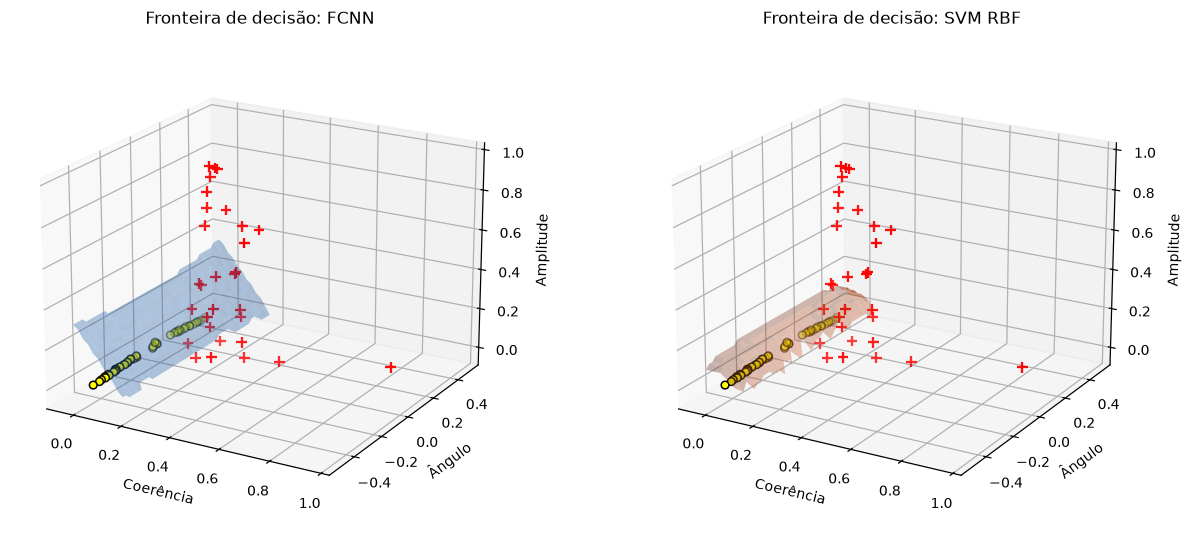

In [8]:
g = [np.linspace(F[..., k].min(), F[..., k].max(), 50) for k in range(3)]
G = np.stack(np.meshgrid(*g, indexing='ij'), axis=-1)            # (50, 50, 50, 3)


def superficie(classes):
    muda = np.diff(classes, axis=2) != 0                          # mudança de classe ao longo da amplitude
    Z = np.interp(muda.argmax(axis=2) + 0.5, np.arange(len(g[2])), g[2])
    Z[~muda.any(axis=2)] = np.nan                                 # coluna sem mudança de classe
    return Z


C1, C2 = np.meshgrid(g[0], g[1], indexing='ij')
fig = plt.figure(figsize=(12, 5))
for p, (nome, classes) in enumerate([('FCNN', fcnn_predict(G, T1, T2)), ('SVM RBF', svm_predict(model, G))]):
    a = fig.add_subplot(1, 2, p + 1, projection='3d')
    a.plot_surface(C1, C2, superficie(classes), alpha=0.35, color=COR['FCNN' if p == 0 else 'SVM'], edgecolor='none')
    plot_treino(a); a.set_title(f'Fronteira de decisão: {nome}'); a.view_init(20, -60)
plt.tight_layout(); plt.show()

### 5.3 Resumo quantitativo

Não há rótulo verdadeiro para todos os pixels. Mesmo assim, a parte rasa da imagem (**iz < 50**) fica acima de todos os refletores e só contém arcos de migração. Então qualquer pixel classificado como refletor ali é certamente um **falso positivo**.

In [9]:
RASO = slice(0, 50)
res_svm_sem_b = svm_predict(model, F, com_b=False)              # como no svmPredict2.m
acc = lambda res: 100 * np.mean(res[iz, ix] == Y)
linhas = {
    'acurácia no treino (%)': [f'{acc(r):.1f}' for r in (res_nn, res_svm, res_svm_sem_b)],
    'pixels classificados refletor (%)': [f'{100 * r.mean():.2f}' for r in (res_nn, res_svm, res_svm_sem_b)],
    'falsos positivos em iz < 50 (px)': [f'{r[RASO].sum()}' for r in (res_nn, res_svm, res_svm_sem_b)],
    'tempo de treino (s)': [f'{t_nn_train:.3f}', f'{t_svm_train:.3f}', '-'],
    'tempo de predição, 40401 px (s)': [f'{t_nn_pred:.3f}', f'{t_svm_pred:.3f}', '-'],
    'nº de parâmetros / vetores de suporte': [f'{T1.size + T2.size}', f"{len(model['alpha'])}", f"{len(model['alpha'])}"],
}
display(pd.DataFrame(linhas, index=['FCNN', 'SVM RBF', 'SVM RBF sem b']).T)
concord = 100 * np.mean(res_nn == res_svm)
concord_sem_b = 100 * np.mean(res_nn == res_svm_sem_b)
print(f'concordância FCNN × SVM: {concord:.2f} %  |  FCNN × SVM sem b: {concord_sem_b:.2f} %')

,FCNN,SVM RBF,SVM RBF sem b
acurácia no treino (%),100.0,100.0,100.0
pixels classificados refletor (%),6.45,7.47,6.44
falsos positivos em iz < 50 (px),0,1,0
tempo de treino (s),0.033,0.039,-
"tempo de predição, 40401 px (s)",0.015,0.025,-
nº de parâmetros / vetores de suporte,100,45,45


concordância FCNN × SVM: 98.99 %  |  FCNN × SVM sem b: 99.64 %


## 6. Análise

In [10]:
from scipy.ndimage import binary_dilation

fp_nn, fp_svm, fp_sem_b = res_nn[RASO].sum(), res_svm[RASO].sum(), res_svm_sem_b[RASO].sum()
so_svm, so_nn = (res_svm == 1) & (res_nn == 0), (res_nn == 1) & (res_svm == 0)
efeito_b = (res_svm == 1) & (res_svm_sem_b == 0)                      # refletor só por causa do b
regiao = np.full(res_nn.shape, 'outros', dtype=object)
regiao[binary_dilation(res_nn == 1, iterations=3)] = 'borda (até 3 px da máscara da FCNN)'
regiao[150:] = 'abaixo da ponta do R3 (iz ≥ 150)'                     # só a cauda curva da difração
regiao[RASO] = 'raso (iz < 50)'
conta = lambda m: '; '.join(f'{r}: {np.sum(m & (regiao == r))}' for r in np.unique(regiao[m])) or 'nenhum'
energia = lambda m: 100 * np.sum(migN[m] ** 2) / np.sum(migN ** 2)

display(Markdown(f'''
**Resultados deste picking**

* **Treino:** a FCNN acerta {acc(res_nn):.1f} % dos 80 pontos de treino e a SVM RBF acerta {acc(res_svm):.1f} %.
* **Imagem inteira:** a FCNN classifica {100 * res_nn.mean():.2f} % dos pixels como refletor e a SVM, {100 * res_svm.mean():.2f} %. As duas concordam em {concord:.2f} % dos pixels.
* **Onde as máscaras diferem:** {so_svm.sum()} px são refletor só na SVM ({conta(so_svm)}) e {so_nn.sum()} px só na FCNN. Esses pixels têm {energia(so_svm | so_nn):.2f} % da energia da imagem.
* **Falsos positivos na parte rasa (iz < 50):** FCNN {fp_nn} px; SVM {fp_svm} px; SVM sem b {fp_sem_b} px.
* **Abaixo da ponta do R3 (iz ≥ 150),** onde só há a cauda da difração: FCNN {res_nn[150:].sum()} px; SVM {res_svm[150:].sum()} px; SVM sem b {res_svm_sem_b[150:].sum()} px.
* **Efeito do b (= {model['b']:+.3f}):** {efeito_b.sum()} px só são refletor por causa dele ({conta(efeito_b)}). Sem o b, como no `svmPredict2.m`, a SVM marca {100 * res_svm_sem_b.mean():.2f} % dos pixels e a concordância com a FCNN passa de {concord:.2f} % para {concord_sem_b:.2f} %.
* **Custo:** treino em {t_nn_train:.2f} s (FCNN, {T1.size + T2.size} parâmetros) e {t_svm_train:.2f} s (SVM, {len(model['alpha'])} vetores de suporte). Predição dos 40 401 pixels em {t_nn_pred:.3f} s e {t_svm_pred:.3f} s.
'''))


**Resultados deste picking**

* **Treino:** a FCNN acerta 100.0 % dos 80 pontos de treino e a SVM RBF acerta 100.0 %.
* **Imagem inteira:** a FCNN classifica 6.45 % dos pixels como refletor e a SVM, 7.47 %. As duas concordam em 98.99 % dos pixels.
* **Onde as máscaras diferem:** 410 px são refletor só na SVM (abaixo da ponta do R3 (iz ≥ 150): 43; borda (até 3 px da máscara da FCNN): 362; outros: 4; raso (iz < 50): 1) e 0 px só na FCNN. Esses pixels têm 0.09 % da energia da imagem.
* **Falsos positivos na parte rasa (iz < 50):** FCNN 0 px; SVM 1 px; SVM sem b 0 px.
* **Abaixo da ponta do R3 (iz ≥ 150),** onde só há a cauda da difração: FCNN 33 px; SVM 76 px; SVM sem b 0 px.
* **Efeito do b (= +0.430):** 417 px só são refletor por causa dele (abaixo da ponta do R3 (iz ≥ 150): 76; borda (até 3 px da máscara da FCNN): 336; outros: 4; raso (iz < 50): 1). Sem o b, como no `svmPredict2.m`, a SVM marca 6.44 % dos pixels e a concordância com a FCNN passa de 98.99 % para 99.64 %.
* **Custo:** treino em 0.03 s (FCNN, 100 parâmetros) e 0.04 s (SVM, 45 vetores de suporte). Predição dos 40 401 pixels em 0.015 s e 0.025 s.


## Discussão

* **Separabilidade.** No espaço (coerência, ângulo, amplitude), os artefatos clicados formam uma nuvem compacta de coerência e amplitude baixas, e os refletores se espalham para valores altos. As classes são separáveis: os dois métodos acertam 100 % dos 80 pontos de treino.
* **Imagens filtradas.** FCNN e SVM removem os arcos de migração e preservam os três refletores, inclusive o trecho fragmentado do mais profundo. O resultado é semelhante à Fig. 1c do lab. As máscaras concordam em 99 % dos pixels, e as imagens filtradas são visualmente idênticas: os pixels em que elas diferem têm só 0,09 % da energia da imagem.
* **A máscara da SVM contém a da FCNN.** Todos os 410 pixels de discordância são "refletor só na SVM". Quase todos (362) formam uma **borda** de até 3 px em volta dos refletores: a faixa de refletor da SVM é um pouco mais larga. Outros 43 ficam **abaixo da ponta do R3**, na cauda curva da difração.
* **Causa: o termo b.** Com b = +0,43, 417 pixels só são classificados como refletor por causa dele. Sem o b, como no `svmPredict2.m`, a SVM marca 6,44 % dos pixels (a FCNN marca 6,45 %), e a concordância sobe para 99,64 %. Esses pixels ficam na **transição entre as classes**: ali as contribuições dos vetores de suporte de refletor e de artefato quase se anulam em $\sum_i\alpha_i y_i K(\mathbf x_i,\mathbf x)$, e o $b>0$ desloca a fronteira a favor de "refletor". A FCNN, com fronteira global e suave (seção 5.2), põe essa transição mais perto da nuvem de refletores e gera uma máscara mais justa.
* **O papel do picking.**
  * **Parte rasa:** os 50 artefatos foram distribuídos pelos arcos rasos (iz de 18 a 63), e todo pixel raso tem algum ponto de treino próximo no espaço de atributos. Por isso, apesar de $b>0$, a SVM só erra 1 px na parte rasa. Num picking concentrado só nos arcos mais fortes, a SVM-RBF marcaria faixas inteiras dessa região como refletor, porque longe dos vetores de suporte $f(\mathbf x)\to b$.
  * **Abaixo dos refletores:** nenhum artefato foi marcado abaixo dos refletores, e é ali que os dois modelos erram. A cauda curva da difração do R3 é coerente e tem amplitude razoável, então "parece" refletor para os 3 atributos: a FCNN mantém 33 px dela e a SVM, 76.
  * **Ponta do R3:** um dos refletores foi marcado na ponta do R3 (ix ≈ 161, iz ≈ 135), sobre a difração da terminação. Isso ensina aos modelos que essa mancha é refletor. Marcar alguns artefatos na cauda abaixo do R3 deve reduzir esses falsos positivos nos dois métodos.
* **Custo e ajuste.** Os dois treinam e classificam a imagem em centésimos de segundo. A FCNN exige escolher arquitetura, passo e número de iterações, e depende da inicialização aleatória (problema não convexo). A SVM resolve um problema convexo e só exige $C$ e $\sigma$, mas o SMO simplificado sorteia $j$, e o resultado pode variar um pouco entre execuções.

**Conclusão.** Com este picking, FCNN e SVM-RBF produzem filtragens praticamente equivalentes: as máscaras concordam em 99 % dos pixels e as imagens filtradas são idênticas a olho. A diferença está só na fronteira: com $b>0$, a SVM marca uma faixa de refletor um pouco mais larga e uma parte maior da cauda de difração abaixo do R3, enquanto a FCNN dá uma máscara mais justa. Sem o $b$, como no código original do lab, as duas máscaras ficam quase iguais (99,64 %). Os erros que restam aos dois métodos vêm de um tipo de artefato que não foi amostrado, a difração abaixo do R3. Por isso, a qualidade da filtragem depende mais dos atributos e de um picking que cubra todos os tipos de artefato do que da escolha do classificador.
